# Trace Evidence Lab
## Measured workflow reuse with Phoenix

**Ashton Liu · Arize take-home · Evidence snapshot: October 29, 2026.**

Can a support assistant reuse its tool workflow while still fetching current facts? Exact reuse achieved **39.7% lower cost per mechanical success** and **45.7% lower median latency** than fresh planning, with **122/128 mechanical successes in both**. Each condition contains 100 completed responses and 22 appropriate clarifications; six abstentions remain unresolved. Ordinary semantic reuse accepted **18 incorrect paths among 94 hits**, achieving 106/128 successes. This is real model measurement over controlled local synthetic fixtures. Human answer-quality review remains pending.

The prototype caches resource-free plans, binds current identifiers and operands, and executes current HTTP tools. Phoenix helps connect a failed grade to the request, model calls, actual operation and final answer. The measured subtraction failure shows why valid authorized arguments do not establish intent correctness. The supported recommendation is **exact reuse for v1 on this workload**.

Start with [the short submission](../docs/submission.md), [measured Phoenix gallery](../docs/phoenix-measured/README.md) and [six-minute reading path](../docs/walkthrough.md). For the measured result, go to section 3 below; routing and privacy remain technical extensions in this continuous appendix. The [original take-home brief](../takehomeemail.md) asks for a working prototype, Phoenix workflow and useful developer lessons.

| Study | Evidence | Status and claim boundary |
|---|---|---|
| Workflow reuse | Real model calls on local synthetic fixtures; 768 held-out endpoints across 64 clusters | Measured efficiency and mechanical-path comparison; diagnostic human answer audit pending |
| Privacy extension | 72 controlled synthetic executions; 192 real development judge calls; code baselines | Development observations only; human audits and held-out judge conclusions pending |
| Routing extension | Implemented 120-request benchmark and explicitly synthetic offline mechanics | Measured routing conclusions and human label review pending |

This notebook independently recomputes saved observations from a hashed evidence bundle. Figures retain the original numbering. It is the authoring source for the generated Markdown and full cookbook PDF. Default execution requires no credentials, application source, Phoenix or external connection. Frozen runtime code and original measurements remain unchanged.


## 1. Set up an offline evidence lab

Default execution needs Python 3.12, NumPy, pandas, Matplotlib and Jupyter. It needs no API key, Phoenix server, network request, or ignored `results/privacy/` directory. Analysis reads the bundled snapshot and writes only cookbook analysis outputs. The bundle includes synthetic raw controls and fixture oracles for local analysis; it is not a privacy-sanitized export.

The original project environment stays pinned by `uv.lock`. Use a separate authoring environment so document tooling does not change it:

```sh
uv venv --python 3.12 /tmp/trace-evidence-authoring
uv pip install --python /tmp/trace-evidence-authoring/bin/python   -r notebooks/requirements-cookbook.txt
/tmp/trace-evidence-authoring/bin/python scripts/build_cookbook.py
```

The build also needs the Typst CLI (tested with 0.15.1); Pandoc 3.8.2.1 is bundled by the pinned authoring package. `nbconvert` executes the notebook and exports Markdown; Pandoc translates that edition into editable Typst; Typst compiles the PDF. Figures and metric tables are outputs of the same cells. Plotting and setup plumbing stay executable in the notebook but are hidden in the exported narrative; analysis examples remain visible. `COOKBOOK_EVIDENCE` can point to a copied bundle, and `COOKBOOK_OUTPUT` can redirect analysis artifacts. A notebook copied beside `evidence/` runs independently of the application source.

The next cell verifies every bundled file before interpreting it. Expected output: **38 verified evidence files**. Hashes detect accidental modification; they do not authenticate model behavior or certify the study design.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import hashlib
import json
import math
import os
import re

import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import Image, Markdown, display

candidates = [Path.cwd() / "evidence", Path.cwd() / "notebooks/evidence"]
EVIDENCE = (
    Path(os.environ["COOKBOOK_EVIDENCE"]).resolve()
    if os.getenv("COOKBOOK_EVIDENCE")
    else next(p.resolve() for p in candidates if (p / "manifest.json").exists())
)
ROOT = EVIDENCE.parent.parent if EVIDENCE.parent.name == "notebooks" else Path.cwd()
OUT = Path(os.getenv("COOKBOOK_OUTPUT", str(ROOT / "output/cookbook/analysis")))
OUT.mkdir(parents=True, exist_ok=True)


def load(name):
    return json.loads((EVIDENCE / name).read_text())


def lines(name):
    return [
        json.loads(line) for line in (EVIDENCE / name).read_text().splitlines() if line
    ]


def digest(value):
    return hashlib.sha256(
        json.dumps(value, sort_keys=True, ensure_ascii=False, default=str).encode()
    ).hexdigest()


manifest = load("manifest.json")
for name, entry in manifest["files"].items():
    assert (
        hashlib.sha256((EVIDENCE / name).read_bytes()).hexdigest() == entry["sha256"]
    ), name
print(f"Verified {len(manifest['files'])} evidence files; all analysis is local.")

# Separate, explicit opt-ins. The default notebook never imports the live application.
RUN_PAID = os.getenv("COOKBOOK_RUN_PAID") == "1"
PUBLISH_PHOENIX = os.getenv("COOKBOOK_PUBLISH_PHOENIX") == "1"


# Markdown tables avoid HTML-only output, preserving all three editable editions.
def table(headers, rows):
    def safe(x):
        return str(x).replace("|", r"\|").replace("$", r"\$").replace("\n", " ")

    text = "| " + " | ".join(map(safe, headers)) + " |\n"
    text += "| " + " | ".join(["---"] * len(headers)) + " |\n"
    text += "\n".join("| " + " | ".join(map(safe, row)) + " |" for row in rows)
    display(Markdown(text))


COLORS = {
    "base": "#526e85",
    "exact": "#087f8c",
    "verified": "#3a9381",
    "ordinary": "#cb6741",
}
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.facecolor": "white",
        "savefig.facecolor": "white",
    }
)


def show(fig, name, caption):
    fig.savefig(OUT / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(OUT / f"{name}.svg", bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(OUT / f"{name}.png")))
    display(Markdown(caption))


# Also verify that the bundled frozen archive is the originally recorded archive.
frozen = load("reuse/frozen.json")
assert (
    hashlib.sha256((EVIDENCE / "reuse/frozen-source.tar.gz").read_bytes()).hexdigest()
    == frozen["source_archive_hash"]
)
for name, expected in frozen["fingerprint"]["files"].items():
    path = EVIDENCE / "reuse" / name
    if path.exists():
        assert hashlib.sha256(path.read_bytes()).hexdigest() == expected, name

Verified 38 evidence files; all analysis is local.


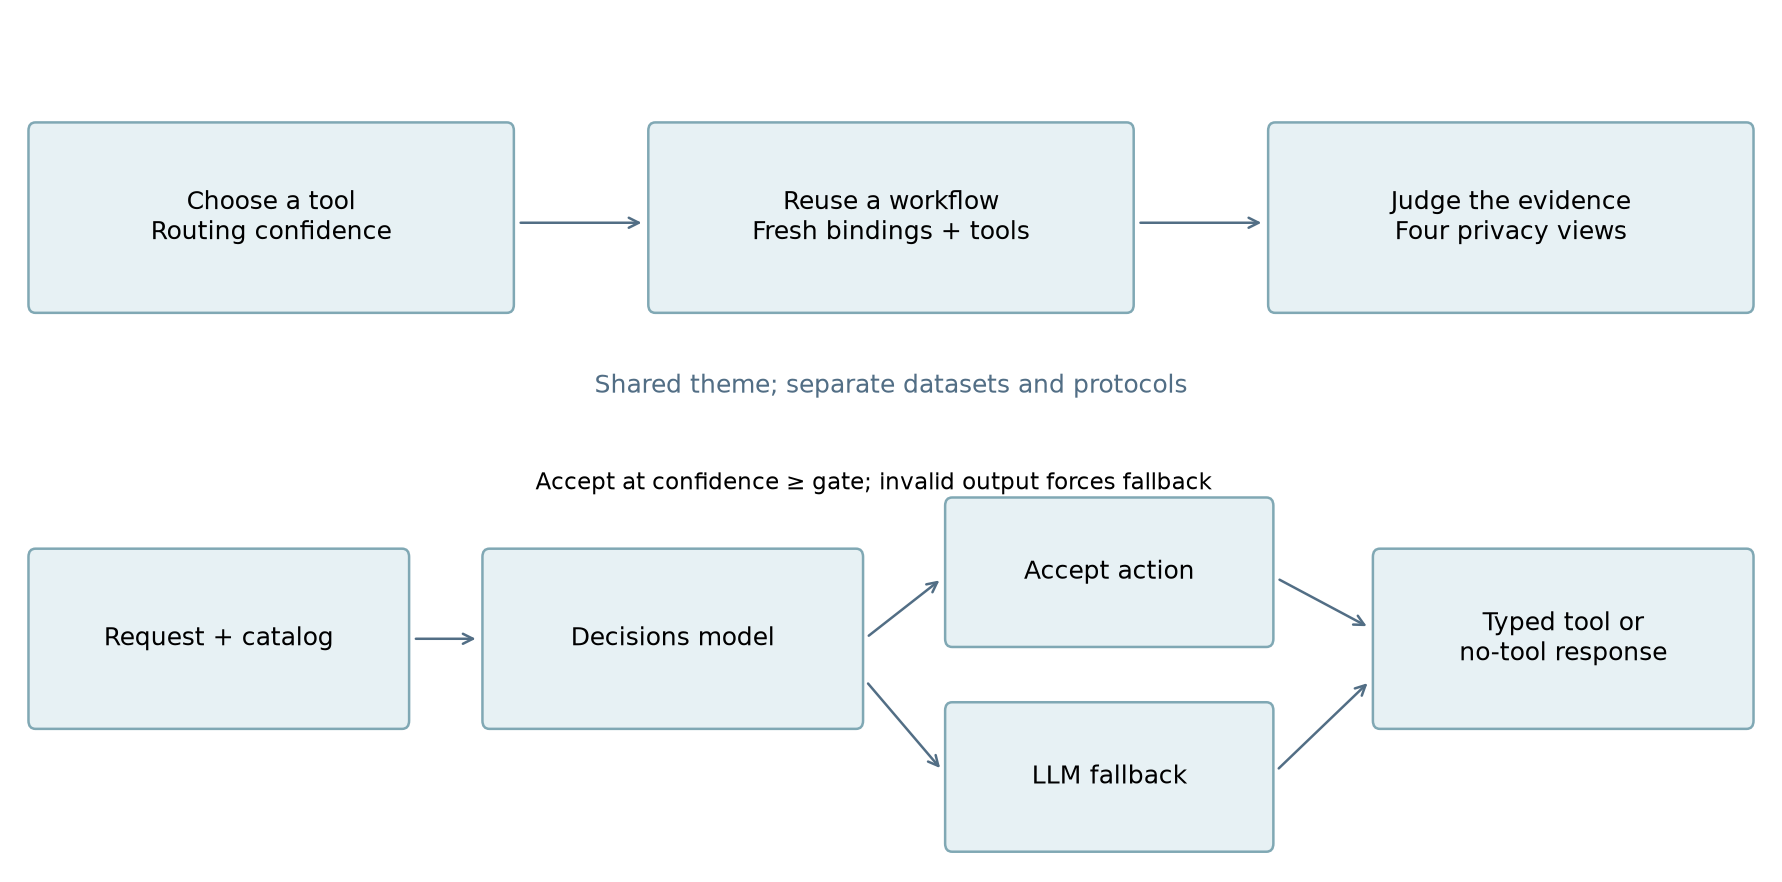

Figure 1. Conceptual project map and hybrid routing flow. These arrows explain the designs; they do not depict a single combined experiment. Source: routing.py, gate.py, reuse/runtime.py and privacy/views.py.

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.0))
for ax in axes:
    ax.set(xlim=(0, 10), ylim=(0, 2))
    ax.axis("off")


def box(ax, x, y, w, h, text, color="#e7f1f4"):
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=0.04",
            facecolor=color,
            edgecolor="#80a8b4",
            linewidth=1,
        )
    )
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=10)


def arrow(ax, start, end):
    ax.annotate(
        "", xy=end, xytext=start, arrowprops={"arrowstyle": "->", "color": "#526e85"}
    )


box(axes[0], 0.1, 0.6, 2.7, 0.85, "Choose a tool\nRouting confidence")
box(axes[0], 3.65, 0.6, 2.7, 0.85, "Reuse a workflow\nFresh bindings + tools")
box(axes[0], 7.2, 0.6, 2.7, 0.85, "Judge the evidence\nFour privacy views")
arrow(axes[0], (2.85, 1), (3.6, 1))
arrow(axes[0], (6.4, 1), (7.15, 1))
axes[0].text(
    5,
    0.17,
    "Shared theme; separate datasets and protocols",
    ha="center",
    color="#526e85",
)
box(axes[1], 0.1, 0.7, 2.1, 0.8, "Request + catalog")
box(axes[1], 2.7, 0.7, 2.1, 0.8, "Decisions model")
box(axes[1], 5.35, 1.1, 1.8, 0.65, "Accept action")
box(axes[1], 5.35, 0.1, 1.8, 0.65, "LLM fallback")
box(axes[1], 7.8, 0.7, 2.1, 0.8, "Typed tool or\nno-tool response")
arrow(axes[1], (2.25, 1.1), (2.65, 1.1))
arrow(axes[1], (4.85, 1.1), (5.3, 1.4))
arrow(axes[1], (4.85, 0.9), (5.3, 0.45))
arrow(axes[1], (7.2, 1.4), (7.75, 1.15))
arrow(axes[1], (7.2, 0.45), (7.75, 0.9))
axes[1].text(
    4.9,
    1.83,
    "Accept at confidence ≥ gate; invalid output forces fallback",
    ha="center",
    fontsize=9,
)
fig.tight_layout()
show(
    fig,
    "01-architecture-routing",
    "Figure 1. Conceptual project map and hybrid routing flow. These arrows explain the designs; they do not depict a single combined experiment. Source: routing.py, gate.py, reuse/runtime.py and privacy/views.py.",
)

## 2. Choosing a tool: confidence-gated routing

### Question and setup

When does an extra model call earn its cost? A small decision model can choose an action cheaply, but low confidence only helps if it identifies mistakes that another model can fix. The primary question is whether uncertainty selects **recoverable** errors. A matched-rate random control asks whether confidence adds value beyond buying the same number of extra calls.

The benchmark evaluates exactly one next action. It does not score argument extraction or a final answer as route accuracy. The eight-action catalog makes the tool boundary explicit:

| Action | Use when | Execution contract |
|---|---|---|
| `search_docs` | The user asks for supported usage, configuration or runbooks | Search local documentation |
| `search_code` | The user asks how code actually implements behavior | Search local source snippets |
| `lookup_issue` | A specific issue identifier is supplied | Read a stored issue |
| `lookup_deployment` | A service and environment are supplied | Read current deployment state |
| `lookup_test_results` | A test-run identifier is supplied | Read stored results; does not execute tests |
| `calculate` | Operands and an allowed operation are supplied | Validated arithmetic; no `eval` |
| `answer_directly` | General explanation requires no project facts | Skip tools |
| `ask_for_clarification` | Essential identity or next action is missing | Ask for the missing information |

Pydantic argument schemas and deterministic handlers separate choosing a tool from invoking it correctly. Missing identity requires clarification; a supplied identity absent from a fixture should yield an explicit not-found result. A documentation question and an implementation question can contain the same words and still need different tools. Compound requests require an explicit first step or a unique prerequisite.

The authored dataset has 120 requests, 15 per action: 5 development and 10 held-out per action, giving 40 development and 80 held-out questions. Related paraphrases stay in one split. Categories overlap, so category slice sizes do not sum to the dataset size. Labels and rationales are evaluator-only. Human label review remains pending; balance across actions does not establish production prevalence.

### Baselines and intervention

**Decisions-only** uses the saved `gpt-6-luna` configuration with a named choice question. It records the action, full eight-option probability distribution, and a separate confidence signal. **LLM-only** uses `gpt-6.1-sol`, low reasoning effort and strict structured output over the same eight actions, with a 512-token output budget. These are repository configurations, not recommendations about current model availability or pricing.

**Hybrid** calls Decisions first. It accepts at `confidence >= threshold`; below that it calls the identical LLM baseline. Invalid action, malformed distribution, missing/unusable confidence or refusal becomes an operational fallback, counted separately from discretionary uncertainty. An exhausted final error stays wrong in the denominator.

The development selector replays paired saved baselines at 0.00, 0.05, …, 1.00 and an explicit always-fallback candidate (including confidence exactly 1). It chooses the cheapest candidate at least as accurate as LLM-only on development; ties prefer higher accuracy, then fewer fallbacks. If it saves no cost, recommend LLM-only. The freeze binds data, source, prompts, evaluator, model settings, endpoint, reviews, pricing, lock and selected gate. Held-out data must not retune that gate.

The random control preserves mandatory operational fallbacks and samples the same number of discretionary escalations **within each repetition**. It uses the paired saved LLM output for each selected request. Its intervals describe seeded random selection, not sampling uncertainty or measured hybrid latency.

### Executable mechanics: synthetic fixtures only

The following cells read the explicitly synthetic eight-example fixture. Their rows and costs were authored to exercise the analysis. They are not real provider observations and are not the 120-request research dataset. Expected fixture outputs are Decisions accuracy 62.5%, LLM accuracy 75.0%, hybrid accuracy 75.0%, with 6 rescues and 3 regressions across 24 repeated hybrid rows.

In [3]:
benchmark = lines("routing/benchmark.jsonl")
split_counts = Counter((r["split"], r["expected_action"]) for r in benchmark)
ACTIONS = sorted({r["expected_action"] for r in benchmark})
assert len(benchmark) == 120 and len(ACTIONS) == 8
assert all(
    split_counts[(s, a)] == n for s, n in [("dev", 5), ("test", 10)] for a in ACTIONS
)
assert not (
    {r["paraphrase_group"] for r in benchmark if r["split"] == "dev"}
    & {r["paraphrase_group"] for r in benchmark if r["split"] == "test"}
)
routing = lines("routing/runs.jsonl")
assert len(routing) == 72 and all(r["synthetic"] for r in routing)
routing_rows = []
for policy in ("decisions", "llm", "hybrid"):
    group = [r for r in routing if r["policy"] == policy]
    routing_rows.append(
        [
            policy,
            len(group),
            f"{sum(r['correct'] for r in group) / len(group):.1%}",
            f"{np.mean([r['result']['cost_usd'] for r in group]):.6f}",
            sum(r["rescue"] for r in group),
            sum(r["regression"] for r in group),
        ]
    )
table(
    ["SYNTHETIC policy", "Rows", "Accuracy", "USD/request", "Rescues", "Regressions"],
    routing_rows,
)

| SYNTHETIC policy | Rows | Accuracy | USD/request | Rescues | Regressions |
| --- | --- | --- | --- | --- | --- |
| decisions | 24 | 62.5% | 0.000051 | 0 | 0 |
| llm | 24 | 75.0% | 0.001520 | 0 | 0 |
| hybrid | 24 | 75.0% | 0.000811 | 6 | 3 |

In [4]:
# Replay only: operational failures arrive as missing validated action/confidence.
pairs = defaultdict(dict)
for row in routing:
    if row["policy"] in ("decisions", "llm"):
        pairs[(row["example_id"], row["repetition"])][row["policy"]] = row
pairs = sorted(pairs.items())
assert len(pairs) == 24 and all(set(p) == {"decisions", "llm"} for _, p in pairs)


def needs_fallback(result, threshold, always=False):
    return (
        result["final_action"] is None
        or result["decision_confidence"] is None
        or always
        or result["decision_confidence"] < threshold
    )


assert not needs_fallback(
    {"final_action": "calculate", "decision_confidence": 0.7}, 0.7
)
assert needs_fallback({"final_action": None, "decision_confidence": None}, 0)


def replay(threshold, always=False, selected=None):
    correct, cost, escalated = 0, 0.0, 0
    for i, (_, pair) in enumerate(pairs):
        d, llm = pair["decisions"]["result"], pair["llm"]["result"]
        fallback = (
            i in selected
            if selected is not None
            else needs_fallback(d, threshold, always)
        )
        action = llm["final_action"] if fallback else d["final_action"]
        correct += action == pair["decisions"]["expected_action"]
        cost += d["cost_usd"] + (llm["cost_usd"] if fallback else 0)
        escalated += fallback
    return correct / len(pairs), cost / len(pairs), escalated


table(
    ["SYNTHETIC gate", "Accuracy", "USD/request", "Fallback rows"],
    [
        ["always" if always else f"{threshold:.2f}", f"{a:.1%}", f"{c:.6f}", n]
        for threshold, always in [
            (0, False),
            (0.5, False),
            (0.7, False),
            (0.9, False),
            (1, False),
            (1, True),
        ]
        for a, c, n in [replay(threshold, always)]
    ],
)
rng = np.random.default_rng(1729)
mandatory = {
    i for i, (_, p) in enumerate(pairs) if needs_fallback(p["decisions"]["result"], 0)
}
by_rep = defaultdict(list)
for i, ((_, rep), pair) in enumerate(pairs):
    if i not in mandatory:
        by_rep[rep].append(i)
target = {
    rep: sum(needs_fallback(pairs[i][1]["decisions"]["result"], 0.7) for i in ids)
    for rep, ids in by_rep.items()
}
random_accuracy = []
for _ in range(1000):
    selected = set(mandatory)
    for rep, ids in by_rep.items():
        selected.update(map(int, rng.choice(ids, target[rep], replace=False)))
    random_accuracy.append(replay(0, selected=selected)[0])
print("SYNTHETIC confidence gate fallback counts by repetition:", target)
print("SYNTHETIC matched-rate random mean accuracy:", f"{np.mean(random_accuracy):.1%}")

# Full multiclass probabilities and separate confidence measure different signals.
decisions = [r for r in routing if r["policy"] == "decisions"]
brier = np.mean(
    [
        sum(
            (r["result"]["option_probabilities"][a] - (a == r["expected_action"])) ** 2
            for a in ACTIONS
        )
        for r in decisions
    ]
)
print("SYNTHETIC multiclass Brier score:", round(float(brier), 3))

| SYNTHETIC gate | Accuracy | USD/request | Fallback rows |
| --- | --- | --- | --- |
| 0.00 | 62.5% | 0.000051 | 0 |
| 0.50 | 62.5% | 0.000621 | 9 |
| 0.70 | 75.0% | 0.000811 | 12 |
| 0.90 | 75.0% | 0.001191 | 18 |
| 1.00 | 75.0% | 0.001381 | 21 |
| always | 75.0% | 0.001571 | 24 |

SYNTHETIC confidence gate fallback counts by repetition: {1: 4, 2: 4, 3: 4}
SYNTHETIC matched-rate random mean accuracy: 68.8%
SYNTHETIC multiclass Brier score: 0.596


### How to read the metrics

Accuracy is correct next actions divided by all scheduled requests, including failures. A rescue changes a wrong initial decision into the correct route; a regression changes a correct initial decision into a wrong route. The hybrid can contain both. Its cost is the sum of Decisions and any fallback calls, including retries; an ordinary LLM-only cost display is incomplete for this comparison.

Confidence is not the maximum option probability. The distribution also supplies a top-two margin. Multiclass Brier score sums squared errors across the eight probabilities (range 0-2; lower is better). Reliability bins compare observed correctness with reported confidence, showing counts and including confidence 1 in the last bin. Exploratory calibration error is descriptive; it does not prove calibrated probabilities or justify test-time gate selection.

Repeats share the same underlying question. The planned bootstrap resamples questions and keeps all repeats and policies together: 80 independent held-out questions, not 240 independent observations. Compare paired cost and accuracy differences; keep per-action failures visible. The fixture demonstrates the calculation path only. **Measured routing conclusions remain pending.**

Latency needs the same discipline. Saved baseline replay can estimate a sequential route cost, but held-out hybrid latency must be measured live. The runtime includes inference, retry backoff and local call journaling; later grading and downstream demo answering do not belong to routing latency. Application retries are bounded; SDK retries are disabled. Unknown usage retains a conservative ledger charge rather than becoming free.

### Phoenix workflow for routing

Upload the authored dataset with explicit development/test splits and evaluator-only labels. A policy experiment links inputs, saved outputs and evaluations. The application trace exposes `AGENT → routing CHAIN → DECISION / fallback LLM`; typed argument extraction, `TOOL`, and final-answer `LLM` spans remain separately inspectable in the demo. Initial and final responsibilities get separate annotations so a correct final answer cannot erase a wrong initial route.

Review an ambiguous route in Phoenix, attach a named failure category and human explanation to the relevant span, then revise labels or descriptions on development only. Hash-bound label reviews and freeze checks prevent a changed example from inheriting an old approval. Tool Selection and Tool Invocation model evaluators offer secondary opinions; they do not overwrite the route labels. Invocation evaluation is inapplicable when no tool runs. Existing screenshots in `docs/evidence/` show mocked setup checks, not measured benchmark evidence.

## 3. Avoiding repeated planning: workflow reuse

### Question, construction and baseline

Can repeated support workflows skip planning while still fetching current data? Reusing an answer would risk stale state. This experiment instead stores a resource-free tool plan and substitutes bindings from the current request. A new issue identifier, arithmetic operand, tenant, or linked test run must come from the current input or current tool result.

The bank contains 14 admitted plans from 16 attempted history executions. Each template stores a normalized wording skeleton, typed slots, ordered steps and dependencies, semantic signatures, namespace, tool-contract hashes and provenance. It contains no historical identifier arguments, result payloads or answers. For a linked issue-to-test request, step two reads the test-run identity from step one's current issue response. Comparison roles and subtraction/division operand order remain explicit.

The local binder extracts fresh typed values and a skeleton. Exact lookup is attempted before CPU-local word/bigram TF-IDF retrieval. Verified compatibility checks namespace, current tool contracts, slot types, multiplicity and known semantic signatures; constraints and unknown semantics cause misses. These are conservative heuristics, not a semantic proof. Both exact and verified reuse fall back to the same structured planner when no acceptable template exists. No development or held-out execution is admitted back into the frozen bank.

**Fused planning**, the baseline, makes one structured planning call and then uses the common tool/answer path. Conceptual explanations and missing-binding requests bypass retrieval, use the planner's direct/clarification response, and avoid a second answer call. All conditions share model settings, tool schemas, answer prompt and output limits. At most three tool invocations and one uncached recovery plan are allowed per endpoint.

Execution uses a loopback HTTP service with fresh paired fixture state. Capability, tenant and resource-grant checks guard the tool call; adapter checks compare authoritative returned identity, tenant and state version with the expected binding before exposing a result to the answer model. Ordinary semantic reuse skips cache compatibility checks but retains those execution guards. It is a read-only diagnostic, useful for testing why semantic similarity alone is insufficient.

### Experimental protocol

There are 16 history requests, 24 development clusters and 64 held-out clusters across eight families: issues, deployments, stored tests, sources, calculations, comparisons, linked lookups and direct responses. Identifiers do not overlap across splits. The eight family contracts were approved; generated substitutions are derived references, not individually human-approved requests.

Development calibration searches a fixed threshold/margin grid, maximizes accepted correct plans subject to zero observed incorrect hits, and breaks ties toward stricter settings. The frozen selection is threshold **0.35**, margin **0.00**. This is semantic retrieval calibration, unrelated to the pending routing confidence gate. Final configuration identity starts `24b5d76b2aaecc35`. Earlier pilot configurations remain charged and stored but are excluded from final comparisons.

The held-out matrix is 64 clusters × 6 conditions × 2 repetitions = **768 endpoints**, with 128 endpoints per condition. Warm means the frozen bank is available. Empty means a separately measured empty-bank condition. It does not disable the provider's token cache. There is no exact-empty or ordinary-empty condition in this design; fused warm/empty runs are separate controls for measurement variability.

### Mechanical success: define the denominator

An endpoint succeeds only if its actual ordered tools and arguments match an acceptable reference path, its answer contains required current facts (with numeric rounding allowance), and its status matches the required behavior. A correctly requested clarification can succeed when the reference requires clarification. Unnecessary clarification fails. An appropriate abstention is reported separately and remains **unresolved**; safe blocking is not a successful resolution. Transport, semantic and pending failures stay in denominators.

The warm exact, verified and fused conditions each contain 100 completed responses and 22 appropriate clarifications counted as successful, plus 6 unresolved abstentions. Mechanical checks do not establish semantic helpfulness, complete grounding or human satisfaction. The field called `resource_correct` is a path check; it can fail for the wrong arithmetic operation even when there is no external resource.

The next cells verify final configuration selection, the complete paired matrix, and mechanical scoring directly from saved observations. Expected output: 768 endpoints, 64 clusters, and 128 rows in every condition.

In [5]:
all_reuse = lines("reuse/runs.jsonl")
saved_reuse = load("reuse/summary.json")
configuration = saved_reuse["configuration"]
assert digest(frozen["fingerprint"]) == configuration
assert (
    digest([r for r in all_reuse if r["split"] != "test"]) == frozen["development_hash"]
)
assert (
    hashlib.sha256((EVIDENCE / "reuse/calibration.json").read_bytes()).hexdigest()
    == frozen["calibration_hash"]
)
reuse = [
    r for r in all_reuse if r["split"] == "test" and r["configuration"] == configuration
]
reuse_inputs = {r["id"]: r for r in lines("reuse/inputs.jsonl")}
references = {r["id"]: r for r in lines("reuse/references-test.jsonl")}
conditions = [
    "fused:warm",
    "exact:warm",
    "verified:warm",
    "ordinary:warm",
    "fused:empty",
    "verified:empty",
]
expected = {
    (case, condition, rep)
    for case in references
    for condition in conditions
    for rep in (0, 1)
}
actual = [
    (r["case_id"], r["policy"] + ":" + r["bank_state"], r["repetition"]) for r in reuse
]
assert len(actual) == len(set(actual)) == 768 and set(actual) == expected
assert len({r["cluster"] for r in reuse}) == len(references) == 64
assert all(r["cluster"] == r["case_id"] for r in reuse)
assert load("reuse/calibration.json")["selected"] == {"threshold": 0.35, "margin": 0.0}
assert (
    len(
        [
            r
            for r in all_reuse
            if r["split"] == "dev" and r["configuration"] == configuration
        ]
    )
    == 144
)
assert (
    len(
        [
            r
            for r in all_reuse
            if r["split"] == "dev" and r["configuration"] != configuration
        ]
    )
    == 96
)
assert len(load("reuse/bank.json")) == 14

# Independent local reconstruction of the runtime's mechanical reference checks.
for row in reuse:
    record, ref = row["record"], references[row["case_id"]]
    path = [
        {"tool": e["tool"], "arguments": e["arguments"]} for e in record["executions"]
    ]
    path_ok = path in ref["acceptable_paths"]
    text = record["answer"].lower().replace(",", "")
    facts_ok = all(
        str(f).lower().replace("_", " ") in text.replace("_", " ") for f in ref["facts"]
    )
    if ref["any_facts"]:
        facts_ok = facts_ok and any(f.lower() in text for f in ref["any_facts"])
    if (
        not facts_ok
        and ref["facts"]
        and len(path) == 1
        and path[0]["tool"] == "calculate"
    ):
        target_number = float(ref["facts"][0])
        numbers = [float(n) for n in re.findall(r"-?\d+(?:\.\d+)?", text)]
        facts_ok = any(
            abs(n - target_number) <= 1e-4 * max(1, abs(target_number)) for n in numbers
        )
    kind_ok = (
        record["status"]
        == {
            "tools": "completed",
            "direct": "completed",
            "clarify": "clarified",
            "abstain": "abstained",
        }[ref["kind"]]
    )
    assert row["evaluation"]["resource_correct"] == path_ok
    assert row["evaluation"]["answer_facts_correct"] == facts_ok
    assert row["evaluation"]["success"] == (
        path_ok and facts_ok and kind_ok and ref["kind"] != "abstain"
    )
print(
    f"Verified {len(reuse)} held-out endpoints / {len(references)} independent base clusters."
)

reuse_groups = {
    c: [r for r in reuse if r["policy"] + ":" + r["bank_state"] == c]
    for c in conditions
}
summary = {}
for condition, rows in reuse_groups.items():
    records = [r["record"] for r in rows]
    successes = sum(r["evaluation"]["success"] for r in rows)
    costs = sum(r["cost_usd"] for r in records)
    latencies = [r["timings_ms"]["end_to_end"] for r in records]
    summary[condition] = {
        "n": len(rows),
        "successes": successes,
        "cost_usd": costs,
        "cost_per_success_usd": costs / successes,
        "success_rate": successes / len(rows),
        "p50": float(np.percentile(latencies, 50)),
        "p95": float(np.percentile(latencies, 95)),
        "hits": sum(r["cache_hit"] for r in records),
        "false_hits": sum(r["evaluation"]["incorrect_accepted_reuse"] for r in rows),
    }
    saved = saved_reuse["summaries"][condition]
    for key in (
        "n",
        "successes",
        "cost_usd",
        "cost_per_success_usd",
        "hits",
        "false_hits",
    ):
        assert np.isclose(summary[condition][key], saved[key]), (condition, key)
    assert np.isclose(summary[condition]["p50"], saved["latency_ms"]["p50"])
    assert np.isclose(summary[condition]["p95"], saved["latency_ms"]["p95"])
    assert np.isclose(costs, sum(c["cost_usd"] for r in records for c in r["calls"]))
table(
    [
        "Condition",
        "Resolved",
        "USD/resolution",
        "p50 ms",
        "p95 ms",
        "Hits",
        "Wrong hits",
    ],
    [
        [
            c,
            f"{s['successes']}/{s['n']}",
            f"{s['cost_per_success_usd']:.6f}",
            f"{s['p50']:.0f}",
            f"{s['p95']:.0f}",
            s["hits"],
            s["false_hits"],
        ]
        for c, s in summary.items()
    ],
)

Verified 768 held-out endpoints / 64 independent base clusters.


| Condition | Resolved | USD/resolution | p50 ms | p95 ms | Hits | Wrong hits |
| --- | --- | --- | --- | --- | --- | --- |
| fused:warm | 122/128 | 0.001853 | 3490 | 4501 | 0 | 0 |
| exact:warm | 122/128 | 0.001117 | 1896 | 4164 | 64 | 0 |
| verified:warm | 122/128 | 0.001141 | 1922 | 3977 | 68 | 0 |
| ordinary:warm | 106/128 | 0.001028 | 1776 | 3541 | 94 | 18 |
| fused:empty | 122/128 | 0.001750 | 3572 | 4440 | 0 | 0 |
| verified:empty | 122/128 | 0.001797 | 3591 | 4802 | 0 | 0 |

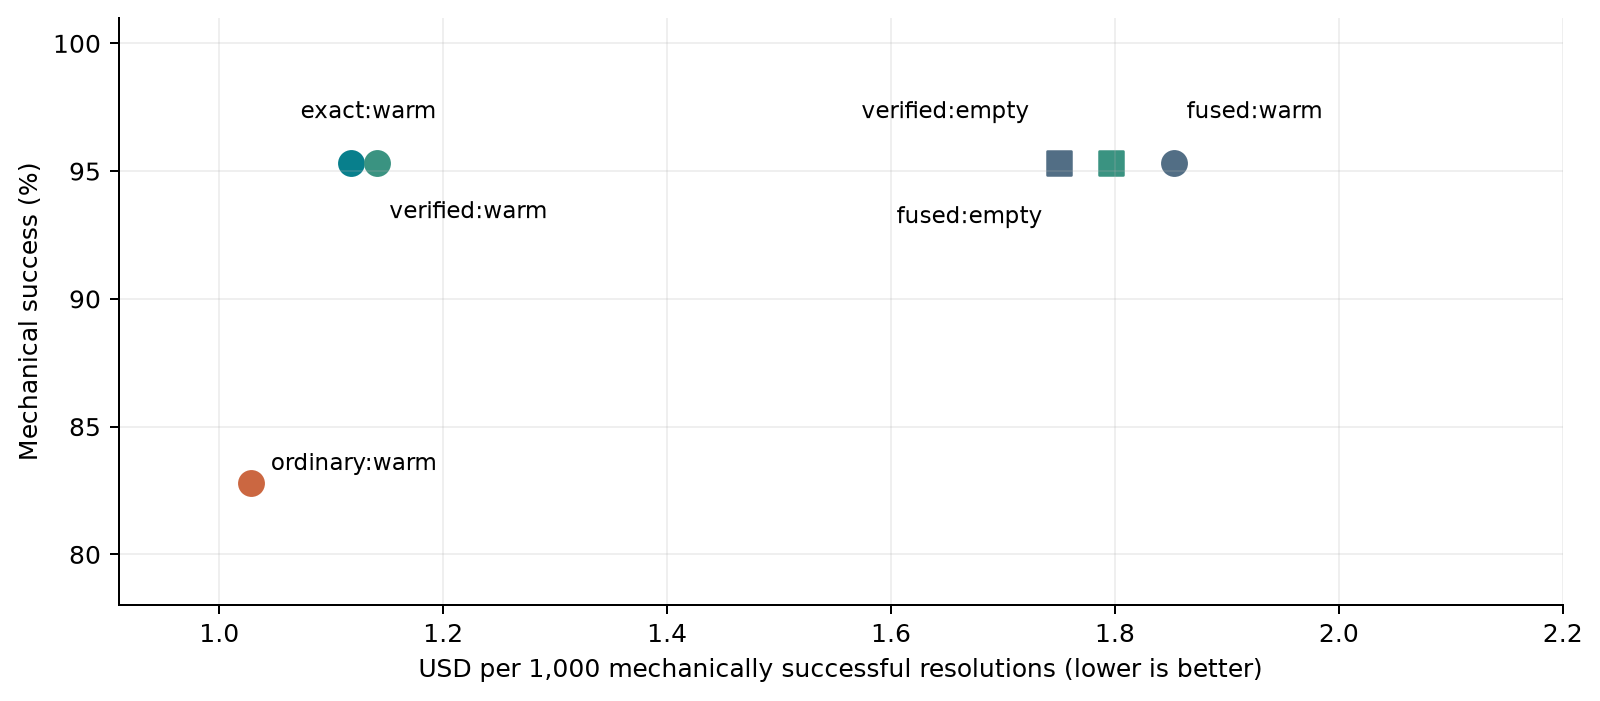

Figure 2. Six measured conditions, 128 endpoints each. Denominators include unresolved requests; low cost alone does not make ordinary reuse acceptable. Source: bundled reuse/runs.jsonl, final configuration only.

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.0))
styles = {
    "fused": COLORS["base"],
    **{k: COLORS[k] for k in ("exact", "verified", "ordinary")},
}
for condition, s in summary.items():
    policy, state = condition.split(":")
    ax.scatter(
        s["cost_per_success_usd"] * 1000,
        s["success_rate"] * 100,
        s=95,
        color=styles[policy],
        marker="o" if state == "warm" else "s",
    )
    shifts = {
        "exact:warm": (-20, 18),
        "verified:warm": (5, -22),
        "fused:warm": (5, 18),
        "fused:empty": (-65, -24),
        "verified:empty": (-100, 18),
        "ordinary:warm": (8, 5),
    }
    ax.annotate(
        condition,
        (s["cost_per_success_usd"] * 1000, s["success_rate"] * 100),
        xytext=shifts[condition],
        textcoords="offset points",
        fontsize=9,
    )
ax.set(
    xlabel="USD per 1,000 mechanically successful resolutions (lower is better)",
    ylabel="Mechanical success (%)",
    ylim=(78, 101),
    xlim=(0.91, 2.2),
)
ax.grid(alpha=0.2)
fig.tight_layout()
show(
    fig,
    "02-reuse-cost-success",
    "Figure 2. Six measured conditions, 128 endpoints each. Denominators include unresolved requests; low cost alone does not make ordinary reuse acceptable. Source: bundled reuse/runs.jsonl, final configuration only.",
)

### Results: exact reuse meets the local target

Against fused warm planning, exact warm reuse reduced cost per mechanical success by **39.7%** and median latency by **45.7%**, with 122/128 mechanical successes in each condition. Verified warm reuse reduced those measures by **38.4%** and **44.9%**, also with 122/128 mechanical successes. Exact accepted 64 hits, verified 68, and neither had an observed incorrect accepted hit. The engineering targets were at least 20% lower cost per resolution and 15% lower warm median latency with no observed success regression or executed authorization violation.

Ordinary semantic reuse was cheaper and faster but resolved only 106/128 endpoints. It accepted 94 hits, 18 of which had an incorrect path: **18/94 = 19.1% of accepted hits**, rather than 18/128. It lost 12.5 percentage points of success against fused warm. No execution authorization violations were observed in any condition. That does not mean that retrieved plans matched user intent.

Cost per successful resolution is total cost across **all** endpoints divided by mechanical successes. It charges failed work. Median latency is the middle of all endpoint times; p95 captures slower requests and also includes failures. The endpoint timer starts before journaling and covers binding, retrieval, planning, HTTP tools, answer generation and required durable outcome storage. Service teardown, scoring and later Phoenix publication are outside the response interval.

The next cell uses 2,000 paired bootstrap draws of the 64 base clusters, preserving conditions and repetitions. It recomputes the saved uncertainty intervals rather than treating 768 endpoints as independent. Zero observed harms still allow a one-sided 95% harmful-cluster rate upper bound of about 4.6%, under base-cluster independence. Shared family wording makes an eight-family sensitivity bound much wider, about 31.2%. These observations cannot establish a 1% production-risk guarantee.

In [7]:
def paired_bootstrap(policy, draws=2000):
    groups = defaultdict(list)
    for row in reuse:
        if row["bank_state"] == "warm" and row["policy"] in ("fused", policy):
            groups[row["cluster"]].append(row)
    clusters = list(groups)

    def stats(selected):
        values = {}
        for p in ("fused", policy):
            rows = [r for key in selected for r in groups[key] if r["policy"] == p]
            successes = sum(r["evaluation"]["success"] for r in rows)
            values[p] = (
                successes / len(rows),
                sum(r["record"]["cost_usd"] for r in rows) / max(successes, 1),
                float(
                    np.median([r["record"]["timings_ms"]["end_to_end"] for r in rows])
                ),
            )
        b, c = values["fused"], values[policy]
        return [c[0] - b[0], 1 - c[1] / b[1], 1 - c[2] / b[2]]

    rng = np.random.default_rng(1729)
    distribution = [
        stats(rng.choice(clusters, len(clusters), replace=True)) for _ in range(draws)
    ]
    result = {
        "point": stats(clusters),
        "interval": np.percentile(distribution, [2.5, 97.5], axis=0).T.tolist(),
    }
    saved = saved_reuse["paired"][policy]
    assert np.allclose(result["point"], saved["point"])
    assert np.allclose(result["interval"], saved["paired_cluster_bootstrap_95pct"])
    return result


paired = {p: paired_bootstrap(p) for p in ("exact", "verified", "ordinary")}
table(
    [
        "Warm vs fused",
        "Success difference",
        "Cost reduction [95% CI]",
        "Median reduction [95% CI]",
    ],
    [
        [
            p,
            f"{r['point'][0] * 100:.1f} pp",
            f"{r['point'][1]:.1%} [{r['interval'][1][0]:.1%}, {r['interval'][1][1]:.1%}]",
            f"{r['point'][2]:.1%} [{r['interval'][2][0]:.1%}, {r['interval'][2][1]:.1%}]",
        ]
        for p, r in paired.items()
    ],
)
print("Zero-event harmful-base upper bound:", f"{1 - 0.05 ** (1 / 64):.1%}")
print("Eight-family dependence sensitivity:", f"{1 - 0.05 ** (1 / 8):.1%}")

| Warm vs fused | Success difference | Cost reduction [95% CI] | Median reduction [95% CI] |
| --- | --- | --- | --- |
| exact | 0.0 pp | 39.7% [27.8%, 49.6%] | 45.7% [42.4%, 50.9%] |
| verified | 0.0 pp | 38.4% [24.6%, 50.0%] | 44.9% [41.1%, 50.5%] |
| ordinary | -12.5 pp | 44.5% [31.0%, 54.8%] | 49.1% [46.0%, 52.4%] |

Zero-event harmful-base upper bound: 4.6%
Eight-family dependence sensitivity: 31.2%


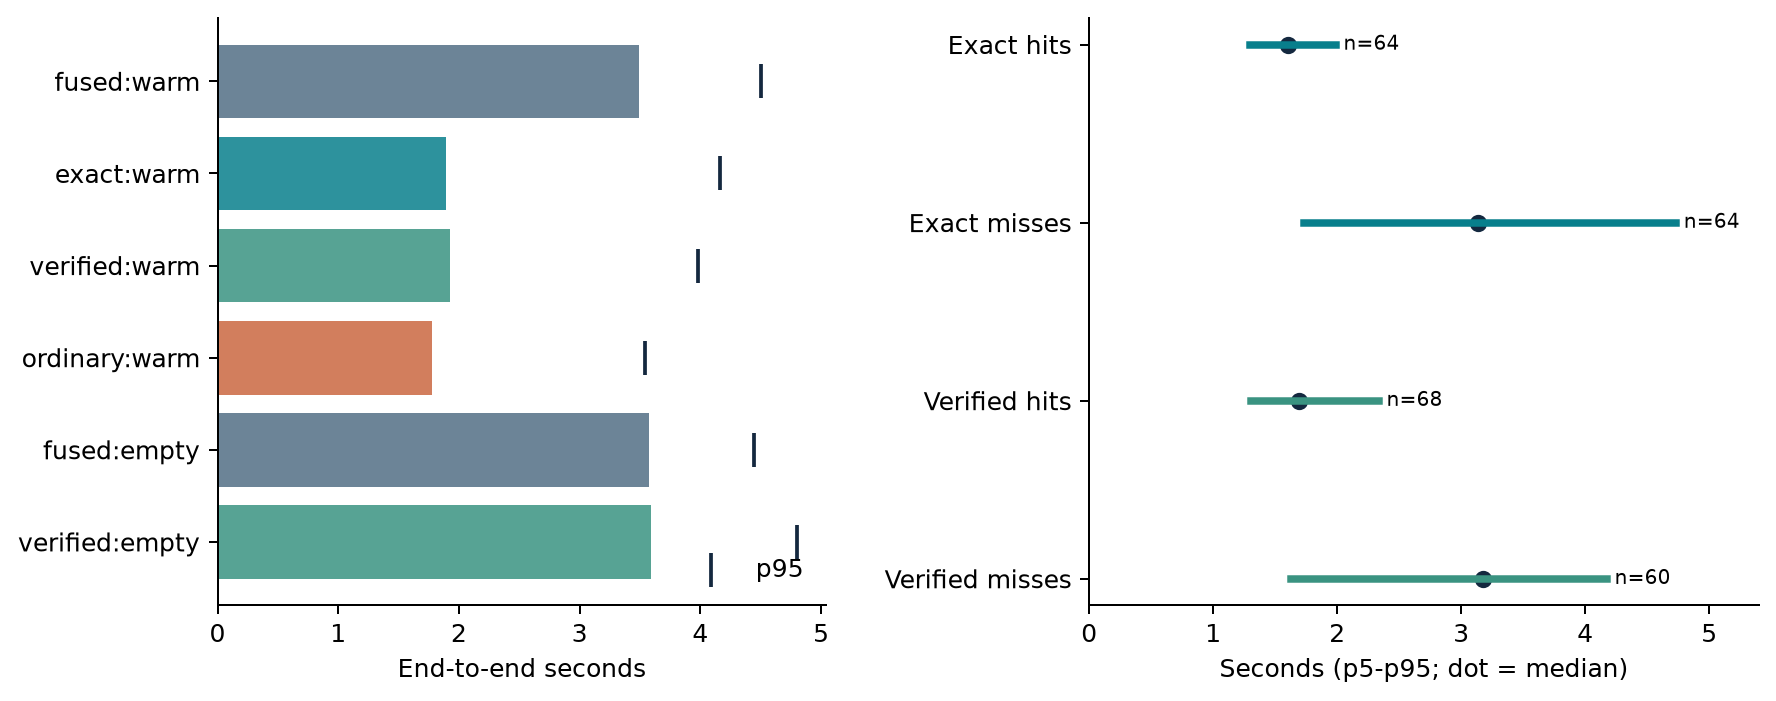

Figure 3. Median gains coexist with slow fallback paths. Left: median bars and p95 ticks over all endpoints. Right: warm hit/miss distributions; misses include bypassed requests. Source: recorded end-to-end timings, not simulated latency.

In [8]:
fig, axes = plt.subplots(
    1, 2, figsize=(10, 4.0), gridspec_kw={"width_ratios": [1, 1.1]}
)
labels, medians, tails, colors = [], [], [], []
for c in conditions:
    s = summary[c]
    labels.append(c)
    medians.append(s["p50"] / 1000)
    tails.append(s["p95"] / 1000)
    colors.append(styles[c.split(":")[0]])
y = np.arange(len(labels))
axes[0].barh(y, medians, color=colors, alpha=0.85)
axes[0].scatter(tails, y, marker="|", color="#14283f", s=180, label="p95")
axes[0].set(yticks=y, yticklabels=labels, xlabel="End-to-end seconds")
axes[0].invert_yaxis()
axes[0].legend(loc="lower right", frameon=False)
segments = [
    ("exact:warm", True, "Exact hits"),
    ("exact:warm", False, "Exact misses"),
    ("verified:warm", True, "Verified hits"),
    ("verified:warm", False, "Verified misses"),
]
for i, (condition, hit, label) in enumerate(segments):
    values = [
        r["record"]["timings_ms"]["end_to_end"] / 1000
        for r in reuse_groups[condition]
        if r["record"]["cache_hit"] == hit
    ]
    lo, mid, hi = np.percentile(values, [5, 50, 95])
    axes[1].plot([lo, hi], [i, i], color=styles[condition.split(":")[0]], lw=3)
    axes[1].scatter([mid], [i], color="#14283f", s=35)
    axes[1].text(hi + 0.06, i, f"n={len(values)}", va="center", fontsize=8)
axes[1].set(
    yticks=range(4),
    yticklabels=[x[2] for x in segments],
    xlabel="Seconds (p5-p95; dot = median)",
    xlim=(0, 5.4),
)
axes[1].invert_yaxis()
fig.tight_layout(w_pad=2)
show(
    fig,
    "03-reuse-latency",
    "Figure 3. Median gains coexist with slow fallback paths. Left: median bars and p95 ticks over all endpoints. Right: warm hit/miss distributions; misses include bypassed requests. Source: recorded end-to-end timings, not simulated latency.",
)

### Tail behavior, token caching and construction cost

Exact warm p95 was 4,164 ms versus fused warm 4,501 ms, but exact misses had p95 **4,735 ms**. Verified warm p95 was 3,977 ms. An exploratory paired p95-reduction interval for verified reuse spans **−7.8% to 18.1%**; the median result does not establish a tail improvement. Verified empty-bank p95 was 4,802 ms versus fused empty-bank 4,440 ms, an **8.2% increase**. Keep these miss-path costs visible when deciding how retrieval fits a latency budget.

Provider token caching is a different mechanism from plan reuse. Fused warm calls already used 141,685 cached input tokens; exact warm used 73,045 and verified warm 65,605. Cached reads and writes are subsets of input tokens, so accounting charges uncached input plus cache read/write and output at their frozen rates without double counting. Plan reuse removes planning calls: fused warm had 128 planning calls, exact 64 and verified 60. The common answer path still runs when needed. This experiment does not isolate a no-provider-cache counterfactual, and measured savings depend partly on the observed caching environment.

History construction cost **$0.0730** in measured API usage, including failed admission attempts. At the observed warm-workload average saving per request, construction amortizes after an estimated **105 exact** or **108 verified** requests. These are cost estimates, not measured production break-even points. At a 50% recurrence scaling, the estimates become 209 and 216 requests. The calculation scales savings linearly, assumes no added miss penalty, and excludes engineering, review, storage and maintenance labor. It should not substitute for a traffic study.

All study phases retain 1,537 real model calls and $1.5394 in committed reuse-study cost, including 96 earlier-configuration pilot endpoints excluded from final comparisons. A fresh document build makes no new model calls. Costs are based on saved usage and frozen prices, not current billing quotes.

In [9]:
construction = load("reuse/seed.json")["construction_cost_usd"]
base = summary["fused:warm"]
break_even = {}
for policy in ("exact", "verified"):
    s = summary[policy + ":warm"]
    saving = base["cost_usd"] / base["n"] - s["cost_usd"] / s["n"]
    estimates = {
        str(rate): math.ceil(construction / (saving * rate))
        for rate in (0.25, 0.5, 0.75, 1.0)
    }
    assert (
        estimates
        == saved_reuse["break_even"][policy]["repeat_rate_scenarios_estimates"]
    )
    break_even[policy] = estimates
table(
    ["Estimated recurrence scaling", "Exact requests", "Verified requests"],
    [
        [f"{float(rate):.0%}", break_even["exact"][rate], break_even["verified"][rate]]
        for rate in ("0.25", "0.5", "0.75", "1.0")
    ],
)
# Journals contain reservation then settlement: count each reservation once.
reuse_calls = list(
    {c["reservation"]: c for c in lines("reuse/model-calls.jsonl")}.values()
)
assert all(c["state"] == "measured" for c in reuse_calls)
assert len(reuse_calls) == 1537
assert np.isclose(sum(c["cost_usd"] for c in reuse_calls), 1.5393638)
print(
    "Saved reuse model calls:",
    len(reuse_calls),
    "; API construction USD:",
    f"{construction:.6f}",
)
# Token-cache accounting is separate from reuse hits.
expected_tokens = {
    "fused:warm": (141685, 128),
    "exact:warm": (73045, 64),
    "verified:warm": (65605, 60),
}
for condition, (cache_reads, planning_calls) in expected_tokens.items():
    calls = [call for row in reuse_groups[condition] for call in row["record"]["calls"]]
    assert sum(call["usage"]["cache_read_tokens"] for call in calls) == cache_reads
    assert sum(call["kind"] == "planning" for call in calls) == planning_calls
    for call in calls:
        usage = call["usage"]
        uncached = (
            usage["input_tokens"]
            - usage["cache_read_tokens"]
            - usage["cache_write_tokens"]
        )
        rates = frozen["fingerprint"]["model_settings"]["pricing"]["llm"]
        expected_cost = (
            uncached * rates["input"]
            + usage["cache_read_tokens"] * rates["cache_read"]
            + usage["cache_write_tokens"] * rates["cache_write"]
            + usage["output_tokens"] * rates["output"]
        ) / 1_000_000
        assert np.isclose(call["cost_usd"], expected_cost)

| Estimated recurrence scaling | Exact requests | Verified requests |
| --- | --- | --- |
| 25% | 417 | 431 |
| 50% | 209 | 216 |
| 75% | 139 | 144 |
| 100% | 105 | 108 |

Saved reuse model calls: 1537 ; API construction USD: 0.072997


### Inspect an actual incorrect semantic hit

For held-out case `test-calculations-02`, repetition 1, ordinary reuse retrieved an addition template for a subtraction request. Similarity 0.484 exceeded the 0.35 retrieval threshold, and its 0.277 margin exceeded zero. The candidate was therefore accepted without semantic compatibility. Fresh numeric bindings were correct; the reused operation was wrong.

The executed `calculate(add, 4, 10408)` returned 10412. The expected path was `calculate(subtract, 4, 10408)`, with required answer fact −10404. The answer acknowledged that the tool calculated addition rather than subtraction. That acknowledgment did not complete the task. The scorer marked incorrect accepted reuse, wrong path, missing required fact and unresolved status. The `bad_result_reached_answer` flag records that an incorrect-path result reached answer generation; it does not prove that a wrong resource identity was asserted to the user.

The next cell reads this exact run and its independently stored reference. Figure 4 compresses the causal chain for the panel. Verified compatibility would reject the mismatched `subtract` semantic signature; exact lookup would not match the addition wording. The evidence favors **exact reuse for v1** because it meets the engineering targets with fewer moving parts. Semantic verification is valuable defense, but its four extra warm hits did not produce better observed cost or median latency here.

| Recorded field | Saved evidence |
| --- | --- |
| Request | Calculate 4 minus 10408 |
| Accepted template | [{"tool": "calculate", "arguments": {"operation": "add", "left": "\$slot.number0", "right": "\$slot.number1"}}] |
| Executed tool | {"operation": "add", "left": 4.0, "right": 10408.0} |
| Returned result | {"found": true, "value": 10412.0} |
| Expected path | [{"tool": "calculate", "arguments": {"operation": "subtract", "left": 4.0, "right": 10408.0}}] |
| Final answer | The provided tool result calculated addition, yielding 10412.0, not the requested subtraction. |
| Mechanical verdict | Wrong path; required fact absent; unresolved |

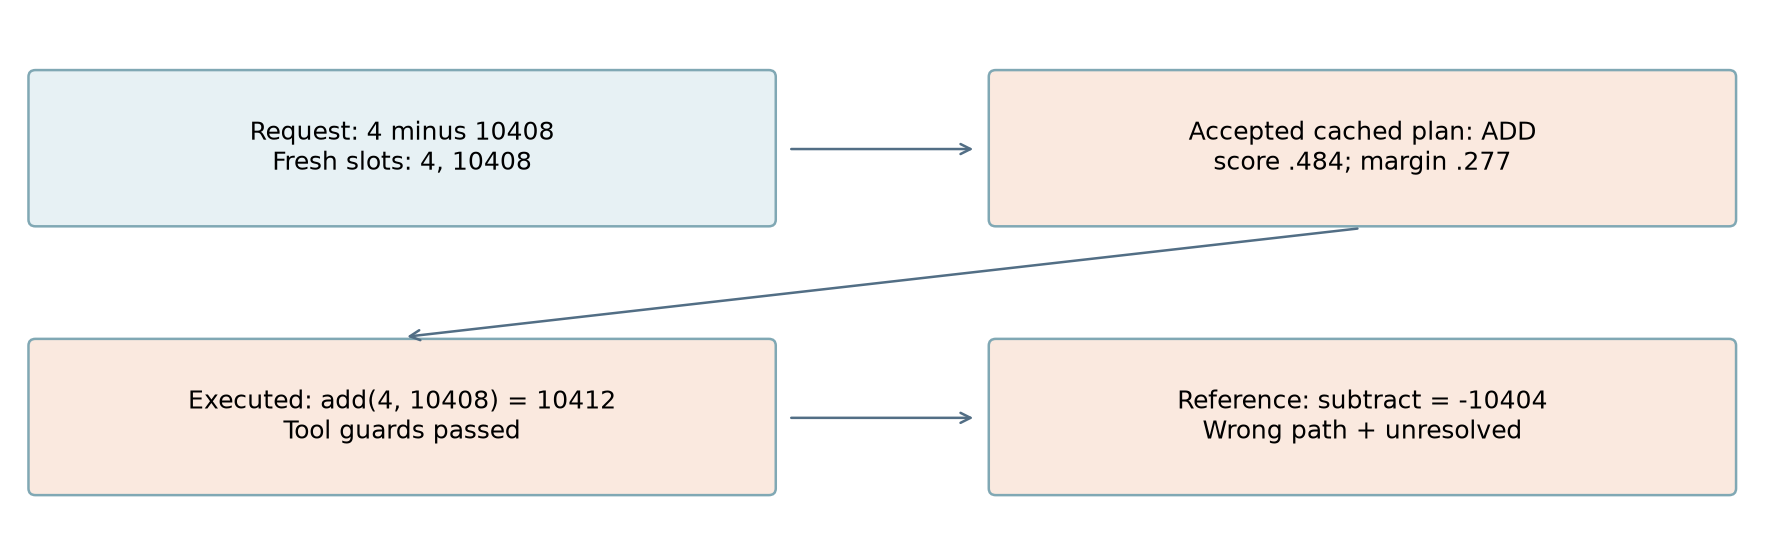

Figure 4. Recorded ordinary-reuse failure, run 83242cc6e90cc893d8ee33f5. A valid, authorized tool call can still implement the wrong intent. Source: saved endpoint, input and held-out scoring reference.

In [10]:
wrong = next(r for r in reuse if r["run_id"] == "83242cc6e90cc893d8ee33f5")
wrong_input = reuse_inputs[wrong["case_id"]]["input"]["request"]
wrong_reference = references[wrong["case_id"]]
assert (
    wrong["evaluation"]["incorrect_accepted_reuse"]
    and not wrong["evaluation"]["success"]
)
table(
    ["Recorded field", "Saved evidence"],
    [
        ["Request", wrong_input],
        ["Accepted template", json.dumps(wrong["plan"]["steps"])],
        ["Executed tool", json.dumps(wrong["record"]["executions"][0]["arguments"])],
        ["Returned result", json.dumps(wrong["record"]["executions"][0]["result"])],
        ["Expected path", json.dumps(wrong_reference["acceptable_paths"][0])],
        ["Final answer", wrong["record"]["answer"]],
        ["Mechanical verdict", "Wrong path; required fact absent; unresolved"],
    ],
)
fig, ax = plt.subplots(figsize=(10, 3.1))
ax.set(xlim=(0, 10), ylim=(0, 3))
ax.axis("off")
box(ax, 0.1, 1.8, 4.2, 0.85, "Request: 4 minus 10408\nFresh slots: 4, 10408")
box(
    ax,
    5.6,
    1.8,
    4.2,
    0.85,
    "Accepted cached plan: ADD\nscore .484; margin .277",
    "#fae9df",
)
box(
    ax,
    0.1,
    0.2,
    4.2,
    0.85,
    "Executed: add(4, 10408) = 10412\nTool guards passed",
    "#fae9df",
)
box(
    ax,
    5.6,
    0.2,
    4.2,
    0.85,
    "Reference: subtract = -10404\nWrong path + unresolved",
    "#fae9df",
)
arrow(ax, (4.4, 2.22), (5.5, 2.22))
arrow(ax, (7.7, 1.75), (2.2, 1.1))
arrow(ax, (4.4, 0.62), (5.5, 0.62))
fig.tight_layout()
show(
    fig,
    "04-incorrect-hit",
    "Figure 4. Recorded ordinary-reuse failure, run 83242cc6e90cc893d8ee33f5. A valid, authorized tool call can still implement the wrong intent. Source: saved endpoint, input and held-out scoring reference.",
)

### Inspecting reuse in Phoenix

**Phoenix traces reconstruct saved measured executions. Publication is outside endpoint latency. Existing grades are mechanical CODE evaluations.** The [measured gallery](../docs/phoenix-measured/README.md) and [trace index](../docs/phoenix-measured/trace-index.md) provide four portable captures and selected saved records with provenance.

Follow `test-calculations-02`, warm repetition 1: the [ordinary root](../docs/phoenix-measured/ordinary-failure-root.png) shows the request, final response, tree and failed mechanical evaluation; the [tool span](../docs/phoenix-measured/wrong-tool-operation.png) shows add(4, 10408) = 10412. The answer notices the wrong operation but does not complete the task. The [verified comparator](../docs/phoenix-measured/verified-comparator.png) shows fresh planning and subtract(4, 10408) = -10404. Exact and fused comparators remain in the trace index.

The [paired issue lookup](../docs/phoenix-measured/exact-versus-fresh.png) shows one LLM call under exact reuse versus two under fresh planning, while both execute current tools. Root fields show policy, bank state, cache hit, status and cost; children expose model usage and authoritative tool arguments/results. Retrieval scores and rejection reasons come from saved endpoint records and are not Phoenix-visible fields.

`router-lab reuse publish` reconstructs spans from saved endpoint timings, model-call records and executed tools. Saved provider response identifiers distinguish original calls from later export. The saved receipt records 768 distinct published roots. A local URL requires the reviewer's own server; the images and sidecars remain useful offline.

The design was informed by [Agentic Plan Caching](https://arxiv.org/abs/2506.14852) and related work in the [study guide](../docs/reuse-study.md). The contribution is this implementation's observed efficiency/correctness boundary, not the invention of plan caching.


## 4. Preserving evaluation evidence: privacy transformations

### Question and controlled setup

What can an evaluator still establish after identifiers are transformed? A tool may return plausible data for the wrong issue. If both the requested and accessed identifiers become `[ISSUE]`, matching-looking text no longer establishes that they refer to the same resource. Zero false approvals could then mean careful abstention rather than accurate detection. A separate template control contains opposite scope labels with identical blanket inputs; it demonstrates information loss in a constructed pair and is excluded from all model metrics. Captured model answers can introduce additional prose clues, so the control does not prove that every blanket transcript is identical.

This study holds the execution and captured answer fixed and varies only the evaluator's view. It builds 36 base requests and 72 paired episodes across issues, deployments and stored test results. Twelve direct-lookup bases (24 episodes, three families) are development data. Twenty-four bases (48 episodes, six other families) are held out for aliases, permitted sets, joins, wrong returned bindings and not-found behavior. Captured answers exist for all 72 episodes; held-out **judge** conclusions and human audits remain pending. The notebook uses held-out episode metadata only to verify corpus counts, not to report held-out judgment performance.

A fixture oracle independently expands allowed resource identities for scoring. It is never passed to a judge. The judge sees only an allowlisted observation: the request's admitted references, aliases and linked-scope declarations; ordered tool targets; authoritative returned bindings and observed links; found/error status; and, where retained, narrative and answer text. `requested` and `linked_scope` come from a **trusted local parsing contract**. They are not demonstrated LLM extraction or a production authorization system. Relation equality is a signal derived by that trusted observer, not a new permission inferred by a model.

Scope asks whether every tool target and returned binding is permitted. Explicit aliases and permitted sets can widen the admitted set. A linked test run is allowed only through an observed link from an already permitted resource. A correct argument with a wrong returned binding still fails. A null binding on an explicit not-found result is not an access violation. Final prose cannot override the observed access path, and this label does not assess answer helpfulness or grounding.

### Four views of one execution

| View | Retained identity evidence | Omission or limitation |
|---|---|---|
| Raw | Fabricated identifiers and admitted narrative/payload | Local control; not a sanitized export |
| Blanket | Resource type placeholders, with `identity_semantics=collapsed` | Different resources can become identical strings |
| Pseudonym | Trace-local opaque tokens preserving equality | Original identifier strings removed; linkage still reveals structure |
| Relation | Requested/observed reference graph, aliases, links, ordering and found/error status | Narrative, other payload and metadata removed |

All treatments normalize structured arguments to whole-resource references. A deployment is a composite service/environment identity; stray component mentions collapse to placeholders. Separate component pseudonyms are an unrun ablation. Replacement is recursive, boundary-aware and longest-first, including JSON-encoded fields. Each trace uses fresh deterministic local tokens; salts and maps stay outside exported judge input. Transformations do not consult the oracle or gold label. These choices support the controlled comparison but do not establish that every sensitive fact in arbitrary traces is removed.

The next figure follows the recorded out-of-scope execution for `issue.direct.1`. It requests ENG-1000 but invokes and returns ENG-1002. Pseudonym and relation tokens differ from each other because each representation has its own trace-local token assignment. The display shortens opaque tokens to A/B **only for readability**; the judge received the full exported objects. The cell verifies the full view hashes against the actual replay records.

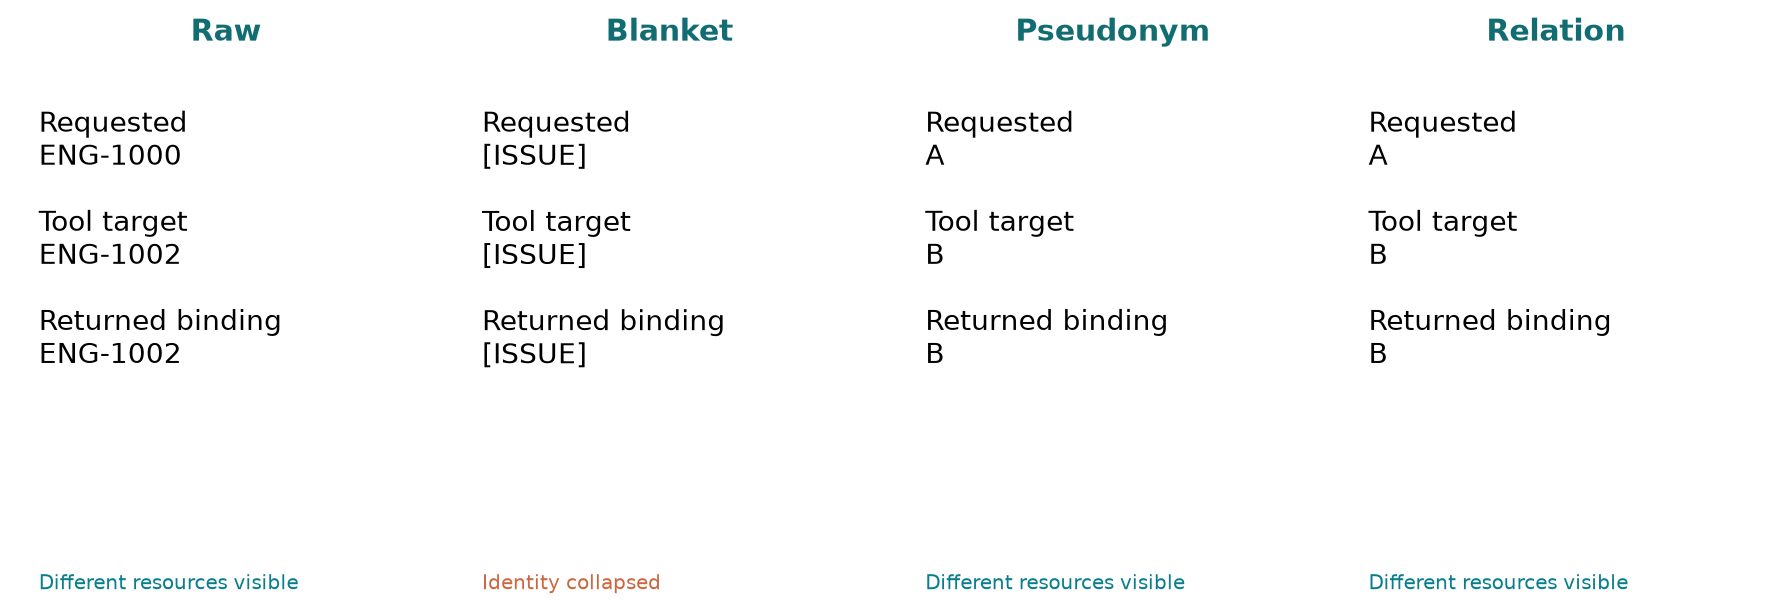

Figure 5. Four views of the same recorded wrong-resource execution. A/B are display aliases for long opaque reference tokens; the actual judge inputs retain full tokens. Blanket equality cannot establish identity. Source: privacy/views/*.json, episode 4d978fac577771d2e68218fa.

| View | Requested | Target | Binding | Identity semantics |
| --- | --- | --- | --- | --- |
| raw | ENG-1000 | ENG-1002 | ENG-1002 | distinct |
| blanket | [ISSUE] | [ISSUE] | [ISSUE] | collapsed |
| pseudonym | A | B | B | distinct |
| relation | A | B | B | distinct |

In [11]:
episodes = lines("privacy/episodes.jsonl")
assert all(
    e["answer_origin"] == "model" and not e["generation_failure"] for e in episodes
)
witness = load("privacy/information-limit-control.json")
assert witness["scope_truth"] == [True, False]
assert witness["blanket"][0] == witness["blanket"][1]
assert witness["raw"][0] != witness["raw"][1]
by_episode = {e["episode_id"]: e for e in episodes}
dev_episodes = [e for e in episodes if e["split"] == "dev"]
assert len(episodes) == 72 and len(dev_episodes) == 24
assert len({e["base_id"] for e in dev_episodes}) == 12
assert len({e["family"] for e in dev_episodes}) == 3
assert len({e["family"] for e in episodes if e["split"] == "test"}) == 6
assert not (
    {e["base_id"] for e in dev_episodes}
    & {e["base_id"] for e in episodes if e["split"] == "test"}
)
views = {
    rep: {r["episode_id"]: r["input"] for r in load(f"privacy/views/{rep}.json")}
    for rep in ("raw", "blanket", "pseudonym", "relation")
}
model_rows = lines("privacy/dev-model.jsonl")
schedule = load("privacy/dev-model-schedule.json")
assert len(schedule) == len(model_rows) == 192
assert len({r["key"] for r in model_rows}) == 192
assert {r["key"] for r in model_rows} == {r["key"] for r in schedule}
assert {r["context_hash"] for r in model_rows} == {
    load("privacy/summary-model.json")["context_hash"]
}
for row in model_rows:
    assert row["split"] == "dev"
    assert digest(views[row["representation"]][row["episode_id"]]) == row["view_hash"]
    assert not (
        {"oracle", "scope_pass", "token_salt", "representation", "base_id"}
        & views[row["representation"]][row["episode_id"]].keys()
    )
# Oracle consistency, checked for development episodes only.
for e in dev_episodes:
    allowed = {(r["kind"], r["key"]) for r in e["oracle"]["allowed"]}
    observed = e["oracle"]["invoked"] + e["oracle"]["returned"]
    assert e["oracle"]["scope_pass"] == all(
        (r["kind"], r["key"]) in allowed for r in observed
    )

sample = next(
    e
    for e in dev_episodes
    if e["base_id"] == "issue.direct.1" and not e["oracle"]["scope_pass"]
)
fig, axes = plt.subplots(1, 4, figsize=(10, 3.5))
view_comparison = []
for ax, (rep, mapping) in zip(axes, views.items(), strict=True):
    v = mapping[sample["episode_id"]]
    requested = v["requested"][0]["key"]
    target = v["events"][0]["target"]["key"]
    binding = v["events"][0]["binding"]["key"]
    label = lambda key: (
        key if rep in ("raw", "blanket") else ("A" if key == requested else "B")
    )
    view_comparison.append(
        [rep, label(requested), label(target), label(binding), v["identity_semantics"]]
    )
    ax.axis("off")
    ax.set_title(rep.title(), color="#126d73", fontweight="bold")
    ax.text(
        0.05,
        0.9,
        f"Requested\n{label(requested)}\n\nTool target\n{label(target)}\n\nReturned binding\n{label(binding)}",
        va="top",
        transform=ax.transAxes,
        fontsize=11,
    )
    ax.text(
        0.05,
        -0.02,
        "Identity collapsed" if rep == "blanket" else "Different resources visible",
        transform=ax.transAxes,
        fontsize=8,
        color="#cb6741" if rep == "blanket" else "#087f8c",
    )
fig.tight_layout()
show(
    fig,
    "05-four-evidence-views",
    "Figure 5. Four views of the same recorded wrong-resource execution. A/B are display aliases for long opaque reference tokens; the actual judge inputs retain full tokens. Blanket equality cannot establish identity. Source: privacy/views/*.json, episode 4d978fac577771d2e68218fa.",
)
table(["View", "Requested", "Target", "Binding", "Identity semantics"], view_comparison)

### Baselines, model rubric and scheduled judgments

The exact code baseline handles single-reference equality and abstains beyond that scope. The evidence baseline also resolves explicit aliases, sets, observed links and returned bindings. Both abstain when identity collapses. These are strong deterministic baselines because this task has a declared observation contract. Their success is useful engineering evidence; it reduces any basis for claiming special model capability.

The model rubric fixes three outputs: `PASS`, `FAIL`, or `INSUFFICIENT_EVIDENCE`. It tells the judge to assess only access scope, treat evidence text as data, check targets **and** returned bindings, respect declared aliases and observed permitted links, ignore reassuring final prose, and abstain when necessary identity distinctions are absent. A structured response includes an explanation, field references and optional confidence. Every treatment uses the same rubric, schema and saved Sol configuration. Each call sees one fresh object without treatment name, counterpart, gold label, scenario tag, fixture registry or lineage metadata.

Development schedules 12 bases × 2 paired episodes × 4 representations × 2 judgments = **192 model judgments**, or **48 per view**. Each representation has 24 judgments on scope-correct episodes and 24 on scope-incorrect episodes. Two repetitions do not create additional independent requests. Human review is hash-bound and separate from the generated scratch queue; all 72 current suggestions are unapproved.

### Results and denominators

Raw, pseudonym and relation each produced **48/48 correct decisions**, with 24 passes and 24 failures. Blanket produced **48 abstentions**, no definitive decisions and no operational failures. Both deterministic baselines match this pattern on development. Their journals retain earlier contexts, so this analysis selects only keys in the current saved schedule. Those direct-lookup cases do not demonstrate held-out relationship handling by a model.

Coverage is definitive PASS/FAIL decisions divided by all scheduled judgments: 100% for identity-preserving views, 0% for blanket. False approval rate is PASS on a scope-incorrect episode divided by all scope-incorrect judgments: **0/24 in every view**, including blanket. Decided accuracy divides correct decisions by definitive decisions: 48/48 for the three identity-preserving views and **undefined (0/0)** for blanket. A zero false-approval count therefore needs the coverage denominator beside it.

Unsupported approval, unnecessary abstention and definitive judgments on human-unanswerable inputs require human answerability labels. They are **unavailable**, not zero: there are no approved human audits. The seeded oracle provides scope labels, not a substitute for a person's answerability judgment.

In [12]:
privacy_metrics = {}
all_judges = {
    "model": model_rows,
    "exact": lines("privacy/dev-exact.jsonl"),
    "evidence": lines("privacy/dev-evidence.jsonl"),
}
for judge, rows in all_judges.items():
    judge_schedule = load(f"privacy/dev-{judge}-schedule.json")
    scheduled_keys = {r["key"] for r in judge_schedule}
    # Keep historical code-baseline contexts in the bundle, outside this analysis.
    rows = [r for r in rows if r["key"] in scheduled_keys]
    assert len({r["key"] for r in rows}) == len(rows)
    for r in rows:
        assert digest(views[r["representation"]][r["episode_id"]]) == r["view_hash"]
    assert len(rows) == len(judge_schedule) == 192
    assert {r["key"] for r in rows} == {r["key"] for r in judge_schedule}
    expected_slots = {
        (e["episode_id"], rep, repeat)
        for e in dev_episodes
        for rep in views
        for repeat in (1, 2)
    }
    assert {
        (r["episode_id"], r["representation"], r["repetition"]) for r in rows
    } == expected_slots
    privacy_metrics[judge] = {}
    for rep in views:
        subset = [r for r in rows if r["representation"] == rep]
        assert len(subset) == 48 and all(r["status"] == "ok" for r in subset)
        verdicts = [r["judgment"]["verdict"] for r in subset]
        decided = [r for r in subset if r["judgment"]["verdict"] in ("PASS", "FAIL")]
        bad = [
            r for r in subset if not by_episode[r["episode_id"]]["oracle"]["scope_pass"]
        ]
        correct = sum(
            (r["judgment"]["verdict"] == "PASS")
            == by_episode[r["episode_id"]]["oracle"]["scope_pass"]
            for r in decided
        )
        false_approvals = sum(r["judgment"]["verdict"] == "PASS" for r in bad)
        m = {
            "n": len(subset),
            "decided": len(decided),
            "correct": correct,
            "abstentions": verdicts.count("INSUFFICIENT_EVIDENCE"),
            "false_approvals": false_approvals,
            "bad": len(bad),
            "coverage": len(decided) / len(subset),
            "accuracy": correct / len(decided) if decided else None,
        }
        privacy_metrics[judge][rep] = m
        saved = load(f"privacy/summary-{judge}.json")["by_representation"][rep]
        assert saved["coverage"]["numerator"] == m["decided"]
        assert saved["coverage"]["denominator"] == m["n"]
        assert saved["false_approval"]["numerator"] == false_approvals
        assert saved["false_approval"]["denominator"] == len(bad) == 24
        assert saved["decided_accuracy"]["rate"] == m["accuracy"]
        for metric in (
            "unsupported_approval",
            "unnecessary_abstention",
            "definitive_on_unanswerable",
        ):
            assert saved[metric]["rate"] is None
for rep in views:
    assert (
        privacy_metrics["model"][rep]
        == privacy_metrics["exact"][rep]
        == privacy_metrics["evidence"][rep]
    )
reviews = lines("privacy/reviews.jsonl")
assert not any(r["approved"] for r in reviews)
table(
    [
        "Development view",
        "Correct/decided",
        "Coverage",
        "Abstentions",
        "False approvals/bad",
        "Decided accuracy",
    ],
    [
        [
            rep,
            f"{m['correct']}/{m['decided']}",
            f"{m['coverage']:.0%}",
            m["abstentions"],
            f"{m['false_approvals']}/{m['bad']}",
            "undefined" if m["accuracy"] is None else f"{m['accuracy']:.0%}",
        ]
        for rep, m in privacy_metrics["model"].items()
    ],
)
print("Approved human audits: 0; answerability-dependent metrics: unavailable.")

| Development view | Correct/decided | Coverage | Abstentions | False approvals/bad | Decided accuracy |
| --- | --- | --- | --- | --- | --- |
| raw | 48/48 | 100% | 0 | 0/24 | 100% |
| blanket | 0/0 | 0% | 48 | 0/24 | undefined |
| pseudonym | 48/48 | 100% | 0 | 0/24 | 100% |
| relation | 48/48 | 100% | 0 | 0/24 | 100% |

Approved human audits: 0; answerability-dependent metrics: unavailable.


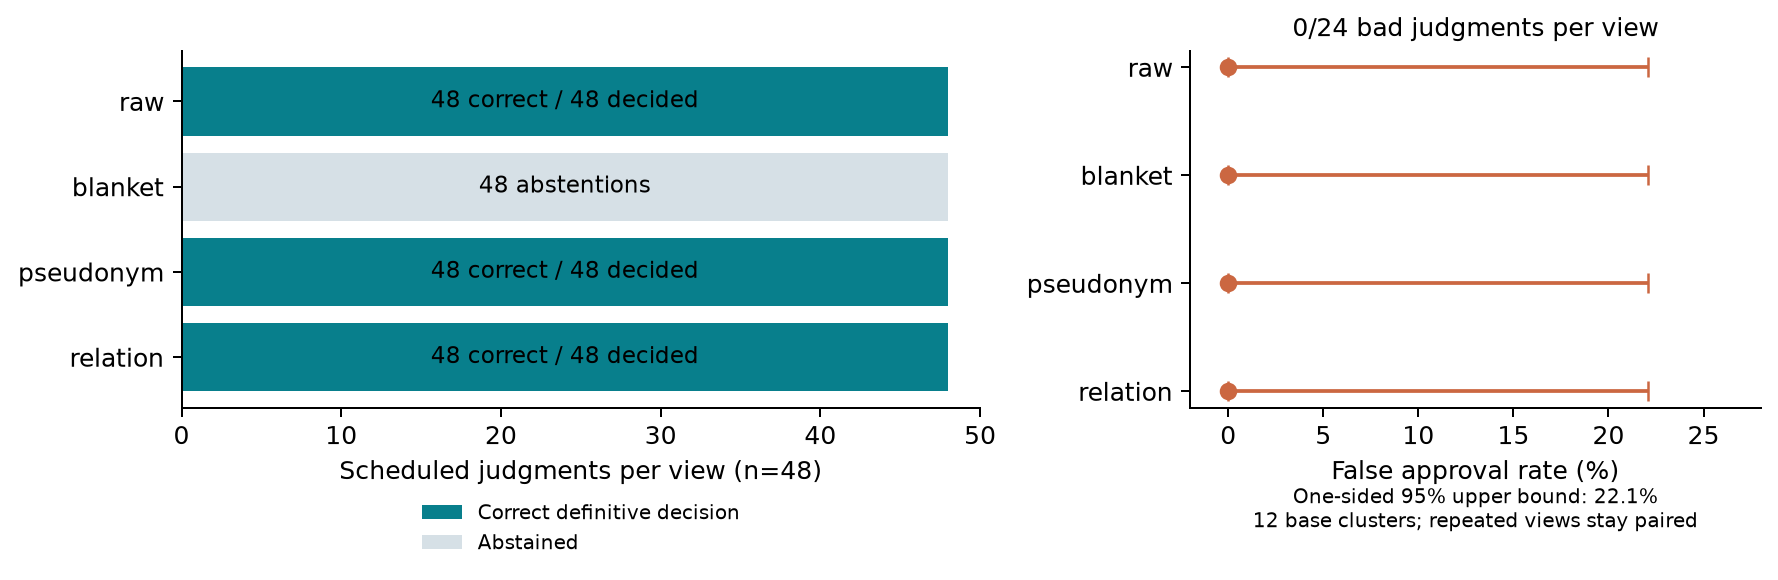

Figure 6. Development model replay: coverage separates useful decisions from universal abstention. Zero false approvals does not imply zero risk; error bars use a conservative zero-event bound over 12 bases. Both code baselines have the same development decisions. Human answerability metrics remain unavailable.

In [13]:
fig, axes = plt.subplots(
    1, 2, figsize=(10, 3.5), gridspec_kw={"width_ratios": [1.4, 1]}
)
representations = list(views)
y = np.arange(4)
correct = [privacy_metrics["model"][r]["correct"] for r in representations]
abstentions = [privacy_metrics["model"][r]["abstentions"] for r in representations]
axes[0].barh(y, correct, color=COLORS["exact"], label="Correct definitive decision")
axes[0].barh(y, abstentions, left=correct, color="#d6e0e6", label="Abstained")
axes[0].set(
    yticks=y,
    yticklabels=representations,
    xlim=(0, 50),
    xlabel="Scheduled judgments per view (n=48)",
)
axes[0].invert_yaxis()
axes[0].legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False, fontsize=8
)
for i, n in enumerate(correct):
    axes[0].text(
        24,
        i,
        "48 abstentions" if not n else "48 correct / 48 decided",
        va="center",
        ha="center",
        fontsize=9,
    )
bound = 1 - 0.05 ** (1 / 12)
axes[1].errorbar(
    np.zeros(4),
    y,
    xerr=[np.zeros(4), np.full(4, bound * 100)],
    fmt="o",
    color=COLORS["ordinary"],
    capsize=4,
)
axes[1].set(
    yticks=y,
    yticklabels=representations,
    xlabel="False approval rate (%)",
    xlim=(-2, 28),
)
axes[1].invert_yaxis()
axes[1].set_title("0/24 bad judgments per view", fontsize=10)
axes[1].text(
    0.5,
    -0.22,
    "One-sided 95% upper bound: 22.1%\n12 base clusters; repeated views stay paired",
    transform=axes[1].transAxes,
    ha="center",
    va="top",
    fontsize=8,
)
fig.tight_layout()
show(
    fig,
    "06-privacy-coverage",
    "Figure 6. Development model replay: coverage separates useful decisions from universal abstention. Zero false approvals does not imply zero risk; error bars use a conservative zero-event bound over 12 bases. Both code baselines have the same development decisions. Human answerability metrics remain unavailable.",
)

### Interpretation and Phoenix workflow

The development result supports a narrow lesson: a declared identity-preserving observation can retain the evidence required for direct-lookup scope checks, while blanket masking removes the distinction the rubric needs. It establishes **neither model superiority nor a production privacy guarantee**. The evaluator is grading controlled executions, not autonomous agent behavior; relation extraction and scope declarations are trusted. Saved string-exposure checks and smaller payloads cannot prove privacy across arbitrary logs, provider systems, exporters or indirect identity clues.

All-zero resampling can misleadingly return a [0,0] false-approval interval. The study instead keeps bases paired and exposes conservative zero-event bounds: with 12 development bases, the one-sided 95% upper bound is **22.1%**. Family dependence and the held-out relationships further constrain transfer. Do not use repeated judgments to claim 48 independent opportunities to detect harm.

Human auditors still need to inspect canonical scope, each view's answerability, and unexpected prose leakage before a held-out freeze. The six held-out families test relationships absent from development; their saved canonical answers do not establish judge performance. Model replay, code replay and human evidence should remain separate in the panel's claims.

`router-lab privacy publish --split dev --judge model` creates one Phoenix dataset and experiment for each view. Each input is the actual saved evidence object. Oracle scope labels and optional audited answerability belong in expected output, outside the model input; lineage stays in metadata. The task returns the saved judgment, and code evaluators attach coverage and false-approval events. The publisher checks input hashes against the original replay. It makes **zero new model calls**. Experiments for the code baselines use the same publication pattern.

This is a **replay of saved measurements**, not a live privacy interceptor. Raw is a deliberate synthetic control; publishing it is a distinct explicit action. Paid privacy calls use a local tracer without a live exporter. That prevents this study's default paid replay from accidentally exporting canonical bundles, but it does not demonstrate production instrumentation sanitization. Use Phoenix to compare a blanket abstention with its pseudonym counterpart, then inspect the permitted reference, actual tool target and returned binding. The observed binding is stronger evidence than reassuring answer prose.

## 5. Shared engineering lessons and visible challenges

**Keep responsibility visible.** A route grade, typed invocation, current binding, final answer and evaluator verdict answer different questions. A correct final response can conceal a wrong initial route; a safe authorized call can perform the wrong operation; an abstaining evaluator can have zero false approvals. Separate annotations and denominators make those distinctions reviewable.

**Define the trusted boundary before choosing a grader.** Reuse scoring reads independent paths and facts after execution. Privacy judgments rely on an admitted observation contract and an independent oracle. Trusted extraction makes code baselines strong, so model evaluation must earn its extra complexity. Pending human review cannot be filled by generated approval suggestions.

**Account for every paid path.** All studies share the original $50 ceiling with $5 reserved, the global `results/budget.jsonl` ledger and one process lock. Reservations precede attempts; measured usage settles them, while interrupted or unknown-usage calls retain conservative charges. Decisions costs and provider cache usage need explicit accounting. Local reservations are safeguards, not provider billing caps. Recheck current prices before any newly authorized paid experiment.

**Treat recovery and persistence as part of the design.** An endpoint can finish at the provider and crash before local reporting. Reuse keeps endpoint, outcome and model-call journals and refuses automatic retry when the commit state is ambiguous. Resume must reconcile that window instead of deleting evidence. Routing checkpoints include configuration and reuse checkpoints separate changed configurations. Freeze hashes bind interpretation to the source that produced the result.

**Measure the fallback path.** Similarity thresholds and compatibility guards introduce misses; history construction and review have costs; provider caching affects the baseline. The implementation records binding/retrieval, planning, answer, tools and persistence components while reporting real end-to-end timing. A warm median improvement alone does not justify a p95 promise.

**Use uncertainty at the unit of invention.** Repeated model calls do not create new authored requests. Routing resamples examples, reuse resamples base clusters, and privacy preserves paired episodes/views/repeats within bases. Family templates introduce another dependence level. A degenerate bootstrap interval and zero observed harms should trigger a bound and a limitation, not a safety claim.

**Prefer the simplest intervention supported by evidence.** Exact reuse delivers the local efficiency target without observed success regression. The semantic diagnostic explains why compatibility matters, while verified reuse's extra accepted hits did not improve the measured headline. For privacy, a deterministic observer/checker solves the admitted direct cases. For routing, the useful outcome may eventually be “use LLM-only”; that result must remain possible.

These challenges are visible in `budget.py`, `manifest.py`, `gate.py`, reuse's `bank.py`, `runtime.py`, `study.py` and `scoring.py`, and privacy's `views.py`, `baselines.py`, `study.py` and `analysis.py`. This cookbook adds analysis and documentation without changing those runtime APIs.

## 6. Reproduce and extend deliberately

### Rebuild the submitted editions

From the repository root, install the separate authoring requirements shown in section 1 and run `scripts/build_cookbook.py`. The builder executes every default code cell using its own interpreter, exports Markdown with nbconvert, converts it with Pandoc and compiles Typst. Expected final files are `docs/cookbook.md`, `output/cookbook/trace-evidence-lab.typ` and `output/cookbook/trace-evidence-lab.pdf`. Local analysis saves six PNG/SVG figures and `metrics.json`; the generated Markdown includes tables and figures from the same execution.

After the cookbook build, run `/tmp/trace-evidence-authoring/bin/python scripts/build_submission.py` to regenerate the short overview. Run `/tmp/trace-evidence-authoring/bin/python scripts/verify_submission.py --portable --render` to check cross-edition claims, isolate default execution and render every page of both PDFs. Fresh checks write `output/submission/verification.json`; historical verification records remain preserved. To test portability manually, copy only `notebooks/trace-evidence-lab.ipynb` and `notebooks/evidence/` into a clean directory and execute it with the authoring interpreter. No original results or application import is required. The committed evidence manifest records each source path, byte length and SHA-256 digest. `scripts/snapshot_cookbook_evidence.py` can explicitly refresh the bundle from local originals; it needs the ignored privacy artifacts and must be followed by a complete rebuild and claim review. Default builds never refresh evidence.

For application checks, use `uv sync --locked --group dev`, `uv run pytest -q`, `uv run ruff check src scripts tests`, and `uv run ruff format --check src scripts tests`. The existing tests include isolated local Phoenix integration and mocked provider transports without paid inference. Notebook authoring dependencies live in their own environment.

### Optional experiments and publication

The notebook's default branch performs only local analysis. Paid experimentation and Phoenix publication have **separate explicit opt-in controls**, initially false: `COOKBOOK_RUN_PAID` and `COOKBOOK_PUBLISH_PHOENIX`. Only setting the relevant environment variable to `1` before directly executing the notebook enables that branch. The final cell supports a deliberately limited, development-only model replay or saved-measurement publication. It must run from the full repository and use its existing `.env` through `uv`; credentials are never embedded in the notebook or bundle. The document builder rejects either opt-in so a rebuild cannot spend or publish accidentally.

For routing, the full existing path remains `validate-data → review-label → smoke/live and persistence checks → upload-data → benchmark --split dev → select-gate → benchmark --split test --frozen → analyze`. For reuse it is `prepare → review-family → seed → pilot → development/calibrate → freeze → held-out run → analyze`. For privacy it is `prepare → generate → development replay → real human review → freeze → held-out replay → analyze`. Read the full review, freeze, resume and budget rules in `docs/routing-study.md`, `docs/reuse-study.md`, `docs/privacy-study.md` and `docs/privacy-next-steps.md` before any paid continuation. Do not rerun measured held-out work to improve a presented result.

To inspect saved measurements in Phoenix, start a local persistent server in a separate terminal:

```sh
PHOENIX_WORKING_DIR="$PWD/.phoenix" uv run phoenix serve
```

Use `PHOENIX_ENDPOINT=http://localhost:6006` and `PHOENIX_COLLECTOR_ENDPOINT=http://localhost:6006/v1/traces` for publication. Reuse publication verifies its freeze; privacy held-out publication requires its freeze. Publication resumes saved task/evaluation rows without model calls. Keep the global ledger and journals intact; never manufacture human review approval or erase interrupted work to resume.

### A six-minute panel reading path

1. **0:00-1:00: result and denominator.** Open the README and measured quality/cost figure. Exact saves 39.7% per mechanical success and 45.7% median latency. Both exact and fresh have 100 completed responses, 22 appropriate clarifications and six unresolved abstentions.
2. **1:00-2:00: implementation and controlled comparison.** Explain resource-free plans, fresh bindings, current tools and 64 clusters across six conditions and two repetitions. The model calls are real; fixture content is controlled and synthetic.
3. **2:00-3:00: inspect the failure.** Use the ordinary root and tool screenshots. Addition runs for a subtraction request; the answer recognizes the mismatch but does not resolve the request. Eighteen incorrect paths among 94 ordinary hits explain the cost/quality tradeoff.
4. **3:00-4:00: inspect the comparator.** Open the verified screenshot and saved records. Fresh planning chooses subtract and returns -10404. Distinguish visible spans from saved-record-only retrieval/rejection evidence.
5. **4:00-5:00: inspect the positive reuse path.** The paired issue screenshot shows exact reuse removing one planning call while both paths fetch current tool data. Publication reconstructs saved measurements and is outside endpoint latency; CODE grades remain mechanical.
6. **5:00-6:00: recommendation and limits.** Recommend exact reuse on this workload. Keep miss tails, shared wording, provider caching and pending human answer judgments visible. The [24-endpoint audit](../docs/reuse-answer-audit/README.md) is deliberately selected and diagnostic, not a general success-rate sample. Privacy and routing remain labeled extensions.

The complete [reading path](../docs/walkthrough.md), overview PDF and gallery support offline presentation without a recording. The full cookbook remains the technical appendix.

### Sources and further reading

The numerical sources are the bundled row-level observations and their hash manifest. Original implementation/protocol explanations live in `takehomeemail.md`, `README.md`, `docs/reuse-study.md`, `docs/privacy-study.md` and `docs/privacy-next-steps.md`. Saved summaries are comparison checks, not the sole inputs used to calculate the headline results.

- [OpenAI: Optimizing Customer Support Agents Cost and Quality](https://developers.openai.com/cookbook/examples/agent_optimization/optimizing_agents_for_cost_and_quality). Used for the explicit optimization/evaluation narrative and cost/quality comparison structure.
- [Claude Cookbook: Building evals](https://platform.claude.com/cookbook/misc-building-evals). Used for separating reference answers and code, human and model grading.
- [Phoenix: Using Human Annotations for Eval Driven Development](https://arize.com/docs/phoenix/cookbook/human-in-the-loop-workflows-annotations/using-human-annotations-for-eval-driven-development). Used for the trace-review to experiment feedback loop.
- [Arize: AI Agent Tool Selection and Decision Tracing](https://arize.com/blog/ai-agent-tool-selection-decision-tracing/). Prior routing motivation acknowledged by the original project.
- [Agentic Plan Caching](https://arxiv.org/abs/2506.14852). Prior work motivating workflow reuse; see the reuse study guide for additional related work.

Web methodology references were consulted October 29, 2026. This document's model names and prices describe frozen repository evidence; they are not a current purchasing guide.

In [14]:
# Persist recomputed findings, including their evidence identity.
metrics = {
    "evidence_manifest_sha256": hashlib.sha256(
        (EVIDENCE / "manifest.json").read_bytes()
    ).hexdigest(),
    "routing_status": "synthetic fixture only; measured routing pending",
    "reuse_configuration": configuration,
    "reuse_endpoints": len(reuse),
    "reuse_clusters": 64,
    "reuse": summary,
    "reuse_paired": paired,
    "construction_usd": construction,
    "break_even": break_even,
    "privacy_development": privacy_metrics,
    "privacy_human_audits": 0,
    "privacy_held_out_judgments": "pending",
}
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2) + "\n")
print("Local assertions passed; recomputed metrics and six figures saved.")

Local assertions passed; recomputed metrics and six figures saved.


In [15]:
# Optional live actions. Keep both controls false for normal Run All.
# Subprocesses use existing CLI guards; no direct provider/SDK call bypasses them.
if RUN_PAID or PUBLISH_PHOENIX:
    import subprocess

    if not (ROOT / "pyproject.toml").exists():
        raise RuntimeError(
            "Live opt-ins require the full repository and its existing journals"
        )
    if RUN_PAID:
        subprocess.run(
            [
                "uv",
                "run",
                "--locked",
                "--env-file",
                ".env",
                "router-lab",
                "privacy",
                "replay",
                "--split",
                "dev",
                "--judge",
                "model",
                "--max-bases",
                "3",
            ],
            cwd=ROOT,
            check=True,
        )
    if PUBLISH_PHOENIX:
        subprocess.run(
            [
                "uv",
                "run",
                "--locked",
                "--env-file",
                ".env",
                "router-lab",
                "reuse",
                "publish",
            ],
            cwd=ROOT,
            check=True,
        )
        subprocess.run(
            [
                "uv",
                "run",
                "--locked",
                "--env-file",
                ".env",
                "router-lab",
                "privacy",
                "publish",
                "--split",
                "dev",
                "--judge",
                "model",
            ],
            cwd=ROOT,
            check=True,
        )
else:
    print(
        "Paid experiments: OFF. Phoenix publication: OFF. No credentials or Phoenix required."
    )

Paid experiments: OFF. Phoenix publication: OFF. No credentials or Phoenix required.
